In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [2]:

import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', encoding='latin-1')

df.head()


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:

df = df[['v1', 'v2']]
df.columns = ['label', 'message']

df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df.head()


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['message'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print(X_train.shape)
print(X_test.shape)


(4457,)
(1115,)


In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=1000)

X_train = vectorizer.fit_transform(X_train).toarray()
X_test = vectorizer.transform(X_test).toarray()

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

print(X_train.shape)
print(X_test.shape)


(4457, 1000)
(1115, 1000)


In [6]:

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

print(sigmoid(0))


0.5


In [7]:

def compute_loss(y_true, y_pred):
    y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return loss

print(compute_loss(np.array([1, 0]), np.array([0.9, 0.1])))


0.10536051565782628


In [8]:

def compute_gradients(X, y, w, b):
    predictions = sigmoid(X @ w + b)
    error = predictions - y

    dw = X.T @ error / len(y)
    db = np.mean(error)

    return dw, db

w = np.zeros(X_train.shape[1])
b = 0.0

dw, db = compute_gradients(X_train, y_train, w, b)

print(dw.shape)
print(db)


(1000,)
0.36582903298182634


In [9]:

def gradient_descent(X, y, lr=2.0, epochs=200):
    w = np.zeros(X.shape[1])
    b = 0.0
    losses = []

    for i in range(epochs):
        dw, db = compute_gradients(X, y, w, b)

        w = w - lr * dw
        b = b - lr * db

        predictions = sigmoid(X @ w + b)
        losses.append(compute_loss(y, predictions))

    return w, b, losses

w_gd, b_gd, loss_gd = gradient_descent(X_train, y_train)

print("Final Loss:", loss_gd[-1])


Final Loss: 0.2199186582514844


In [10]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prob_gd = sigmoid(X_test @ w_gd + b_gd)
y_pred_gd = (y_prob_gd >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_gd))
print("Precision:", precision_score(y_test, y_pred_gd, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gd, zero_division=0))
print("F1:", f1_score(y_test, y_pred_gd, zero_division=0))
print("Loss:", compute_loss(y_test, y_prob_gd))


Accuracy: 0.8977578475336323
Precision: 1.0
Recall: 0.2348993288590604
F1: 0.3804347826086957
Loss: 0.22175809508462707


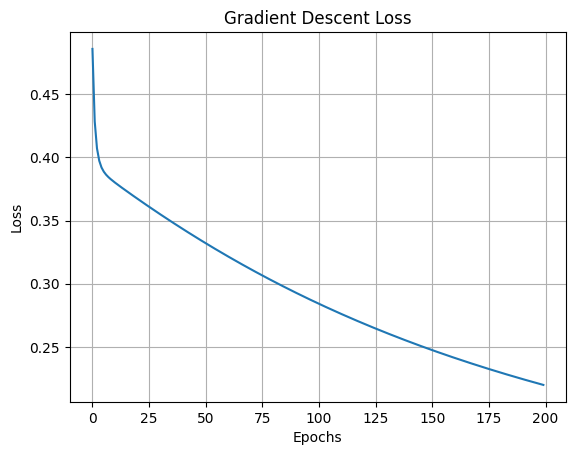

In [11]:

import matplotlib.pyplot as plt

plt.plot(loss_gd)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss')
plt.grid(True)
plt.show()
